# IPL 2008–2019: team records, toss decisions and match outcomes

This report uses the match-level table to examine team win rates, toss outcomes, chasing results and venue patterns. Counts and denominators are reported together. Ball-by-ball data is not needed for these questions, so it is not included in the submission.

## Data and scope

Source: [ipldata](https://www.kaggle.com/datasets/nowke9/ipldata). This report uses the uploaded snapshot, not live data.

`id` identifies a match and `season` is the supplied competition season. `team1`, `team2`, `winner`, `toss_winner` and `toss_decision` describe teams and outcomes. `result` distinguishes normal, tie and no-result records; `dl_applied` flags adjusted matches. `win_by_runs` and `win_by_wickets` give the winning margin. `city`, `venue`, `date`, `player_of_match` and the umpire columns provide context. The supplied season is retained even when a date is unusual.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def data_path(filename):
    # Works after extracting this ZIP, or after attaching its data on Kaggle.
    for folder in (Path("data"), Path(".")):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    kaggle = Path("/kaggle/input")
    matches = sorted(kaggle.rglob(filename)) if kaggle.exists() else []
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Place {filename} in data/, or attach its dataset on Kaggle. Found {len(matches)} Kaggle matches.")

In [2]:
raw = pd.read_csv(data_path("matches.csv"))
print(f"Raw matches: {len(raw):,}; columns: {raw.shape[1]}")
assert len(raw)>=150 and raw.shape[1]>=3
display(raw.head()); display(raw.isna().sum().to_frame("missing"))
display(raw.result.value_counts(dropna=False).to_frame("matches"))

Raw matches: 756; columns: 18


,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


,missing
id,0
season,0
city,7
date,0
team1,0
team2,0
toss_winner,0
toss_decision,0
result,0
dl_applied,0


,matches
result,
normal,743
tie,9
no result,4


## Cleaning team names and defining outcomes

Delhi Daredevils is combined with Delhi Capitals, Kings XI Punjab with Punjab Kings if present, and the two spellings of Rising Pune Supergiant are combined. Deccan Chargers and Sunrisers Hyderabad remain separate team identities. Missing cities and umpires do not remove a usable result. Dates are parsed with mixed formats and checked against season labels; season-based analysis uses the supplied season. Exact duplicate rows are removed, while duplicate IDs trigger an error rather than a silent choice.

Unparsed dates: 0; year/season mismatches: 0
Decided matches: 752; normal unadjusted matches with unambiguous margin: 724


,count,mean,std,min,25%,50%,75%,max
win_by_runs,756.000,13.283,23.471,0.000,0.000,0.000,19.000,146.000
win_by_wickets,756.000,3.351,3.388,0.000,0.000,4.000,6.000,10.000


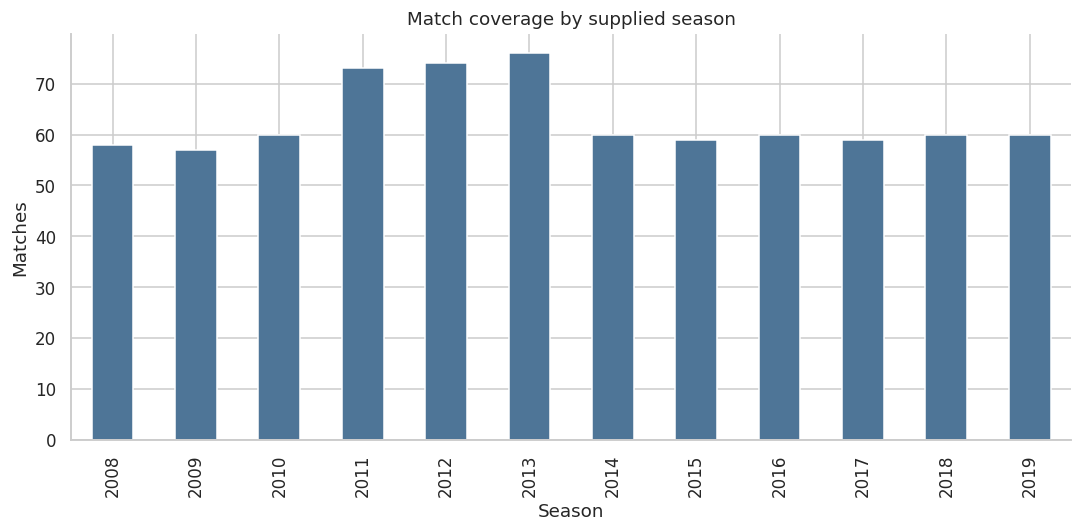

In [3]:
df = raw.drop_duplicates().copy()
assert not df.id.duplicated().any()
aliases = {"Delhi Daredevils":"Delhi Capitals","Kings XI Punjab":"Punjab Kings","Rising Pune Supergiants":"Rising Pune Supergiant"}
for col in ["team1","team2","winner","toss_winner"]:
    df[col] = df[col].replace(aliases)
df["parsed_date"] = pd.to_datetime(df.date,format="mixed",dayfirst=True,errors="coerce")
print(f"Unparsed dates: {df.parsed_date.isna().sum()}; year/season mismatches: {(df.parsed_date.dt.year.ne(df.season)&df.parsed_date.notna()).sum()}")
decided = df[df.winner.notna()].copy()
regular = df[df.result.eq("normal") & df.dl_applied.eq(0) & df.winner.notna()].copy()
regular["toss_won_match"] = regular.toss_winner.eq(regular.winner)
regular["chase_win"] = regular.win_by_wickets.gt(0)
regular["bat_first_win"] = regular.win_by_runs.gt(0)
regular = regular[regular.chase_win ^ regular.bat_first_win].copy()
print(f"Decided matches: {len(decided)}; normal unadjusted matches with unambiguous margin: {len(regular)}")
display(df[["win_by_runs","win_by_wickets"]].describe().T)
df.groupby("season").size().plot.bar(color="#4e7597")
plt.ylabel("Matches"); plt.xlabel("Season"); plt.title("Match coverage by supplied season")
plt.tight_layout(); plt.show()

## 1. Which teams have the strongest win rates?

`concat()` stacks the two team columns to count appearances in decided matches. Wins are divided by those appearances. Ties with a recorded winner are included in team records; no-result matches without a winner are excluded. Teams need at least 30 decided matches to enter the ranked chart.

,decided_matches,wins,win_rate_pct
Chennai Super Kings,164,100,60.976
Mumbai Indians,187,109,58.289
Sunrisers Hyderabad,108,58,53.704
Rajasthan Royals,145,75,51.724
Kolkata Knight Riders,178,92,51.685
Rising Pune Supergiant,30,15,50.000
Royal Challengers Bangalore,177,84,47.458
Punjab Kings,176,82,46.591
Delhi Capitals,175,77,44.000
Gujarat Lions,30,13,43.333


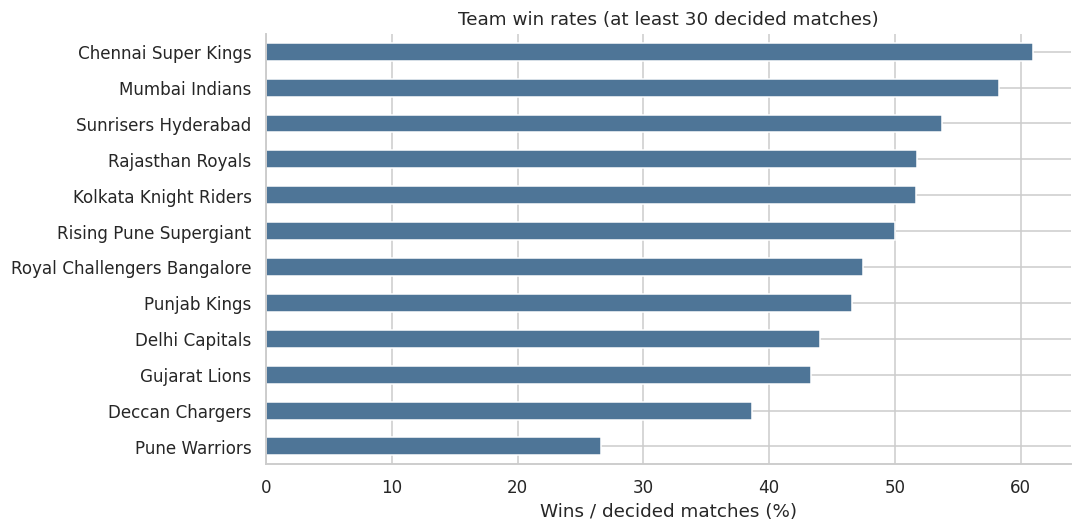

In [4]:
appearances = pd.concat([decided.team1,decided.team2]).value_counts()
wins = decided.winner.value_counts()
teams = pd.DataFrame({"decided_matches":appearances,"wins":wins}).fillna(0)
teams["win_rate_pct"] = teams.wins/teams.decided_matches*100
eligible = teams[teams.decided_matches>=30].sort_values("win_rate_pct",ascending=False)
display(teams.sort_values("win_rate_pct",ascending=False))
eligible.win_rate_pct.sort_values().plot.barh(color="#4e7597")
plt.xlabel("Wins / decided matches (%)"); plt.title("Team win rates (at least 30 decided matches)")
plt.tight_layout(); plt.show()

**Answer.** Chennai Super Kings has the highest win rate among eligible teams (61.0%), with 100 wins in 164 decided matches. The teams did not all compete in the same seasons, so opposition and competition conditions differ.

## 2. How often does the toss winner also win the match?

Only normal, non-D/L matches with unambiguous results are used. `agg()` reports both the number of matches and the mean of a Boolean flag; that mean is the observed win proportion. The split by toss decision describes choices teams made, not a randomised experiment.

,count,sum,win_rate_pct
toss_decision,,,
bat,282,131,46.454
field,442,247,55.882


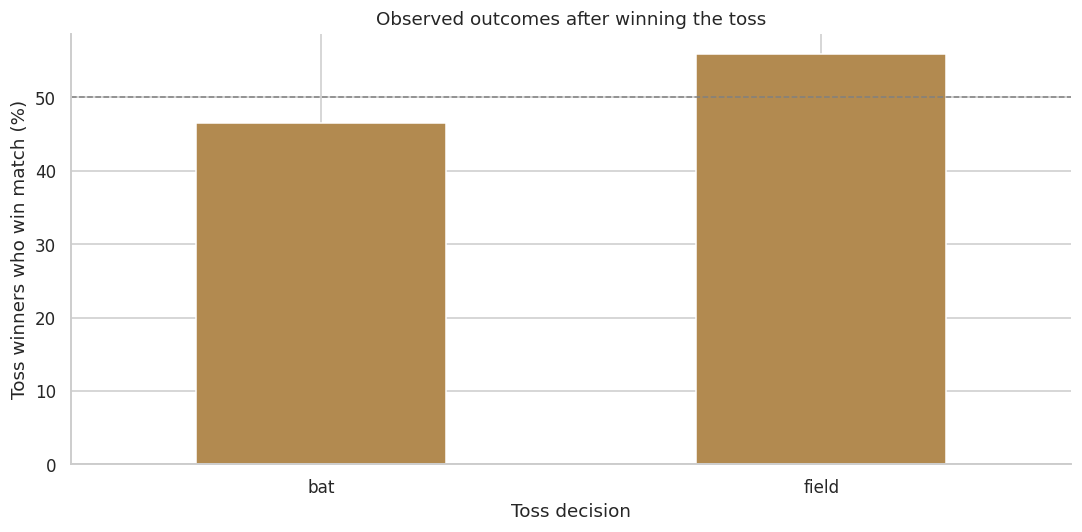

In [5]:
toss = regular.groupby("toss_decision").toss_won_match.agg(["count","sum","mean"])
toss["win_rate_pct"] = toss["mean"]*100
display(toss[["count","sum","win_rate_pct"]])
toss.win_rate_pct.plot.bar(color="#b28a50",rot=0)
plt.axhline(50,color="grey",ls="--",lw=1)
plt.ylabel("Toss winners who win match (%)"); plt.xlabel("Toss decision")
plt.title("Observed outcomes after winning the toss"); plt.tight_layout(); plt.show()

**Answer.** Toss winners win 52.2% of the 724 eligible matches. Choosing to field or bat is linked to conditions and team preferences, so the difference between these groups cannot establish the causal benefit of a toss decision.

## 3. Does the observed chasing win rate change across seasons?

A positive wicket margin identifies a chase win in the eligible subset. Seasonal rates use normal unadjusted matches only. The table includes denominators because season counts differ.

,count,sum,chasing_win_pct
season,,,
2008,56,34,60.714
2009,53,28,52.830
2010,59,28,47.458
2011,69,37,53.623
2012,74,40,54.054
2013,74,37,50.000
2014,58,36,62.069
2015,54,23,42.593
2016,56,38,67.857


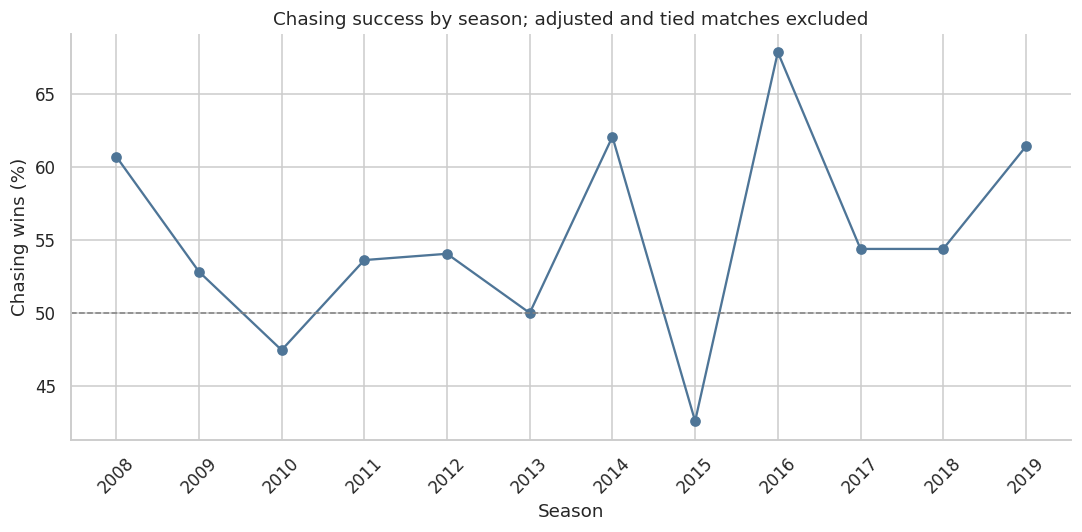

In [6]:
chasing = regular.groupby("season").chase_win.agg(["count","sum","mean"])
chasing["chasing_win_pct"] = chasing["mean"]*100
display(chasing[["count","sum","chasing_win_pct"]])
chasing.chasing_win_pct.plot(marker="o",color="#4e7597")
plt.axhline(50,color="grey",ls="--",lw=1)
plt.xlabel("Season"); plt.ylabel("Chasing wins (%)"); plt.title("Chasing success by season; adjusted and tied matches excluded")
plt.xticks(chasing.index,rotation=45); plt.tight_layout(); plt.show()

**Answer.** The overall chasing win rate is 55.0%. It ranges from 42.6% in 2015 to 67.9% in 2016. These seasonal differences may reflect team strength, venues, conditions and sampling variation.

## 4. Which frequently used venue labels show the highest chasing win rates?

Venues need at least 20 eligible matches. Venue names are kept as supplied because apparently similar labels are not merged without a verified stadium mapping. This means the unit is a venue label, not necessarily a unique physical ground.

,count,sum,chasing_win_pct
venue,,,
Sawai Mansingh Stadium,46,32,69.565
Maharashtra Cricket Association Stadium,21,14,66.667
Eden Gardens,73,43,58.904
"Rajiv Gandhi International Stadium, Uppal",53,31,58.491
"Punjab Cricket Association Stadium, Mohali",35,20,57.143
M Chinnaswamy Stadium,67,38,56.716
Wankhede Stadium,72,37,51.389
Feroz Shah Kotla,63,32,50.794
"MA Chidambaram Stadium, Chepauk",48,18,37.500


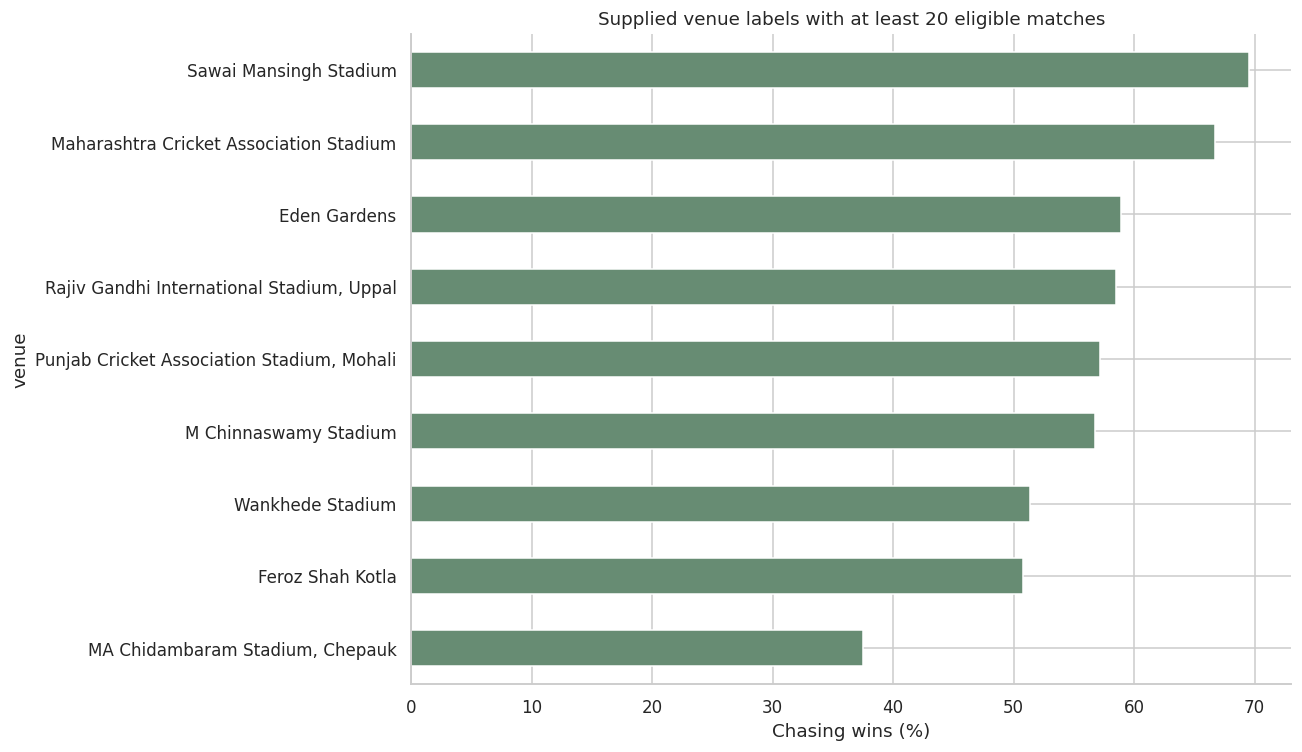

In [7]:
venue = regular.groupby("venue").chase_win.agg(["count","sum","mean"])
venue["chasing_win_pct"] = venue["mean"]*100
venue = venue[venue["count"]>=20].sort_values("chasing_win_pct",ascending=False)
display(venue[["count","sum","chasing_win_pct"]])
venue.chasing_win_pct.sort_values().plot.barh(color="#678c73",figsize=(12,7))
plt.xlabel("Chasing wins (%)"); plt.title("Supplied venue labels with at least 20 eligible matches")
plt.tight_layout(); plt.show()

**Answer.** Sawai Mansingh Stadium has the highest chasing win rate among eligible venue labels (69.6% across 46 matches). This does not isolate a ground effect: home teams, opponents, seasons and toss choices are also involved.

## 5. How are winning margins distributed?

Run margins apply to wins batting first and wicket margins to wins chasing. They are plotted separately because a run and a wicket are not interchangeable measures. Zero margins from the other outcome type are excluded.

,run_margins
count,326.000
mean,30.169
std,27.377
min,1.000
25%,12.000
50%,22.000
75%,39.000
max,146.000


,wicket_margins
count,398.000
mean,6.216
std,1.820
min,1.000
25%,5.000
50%,6.000
75%,7.000
max,10.000


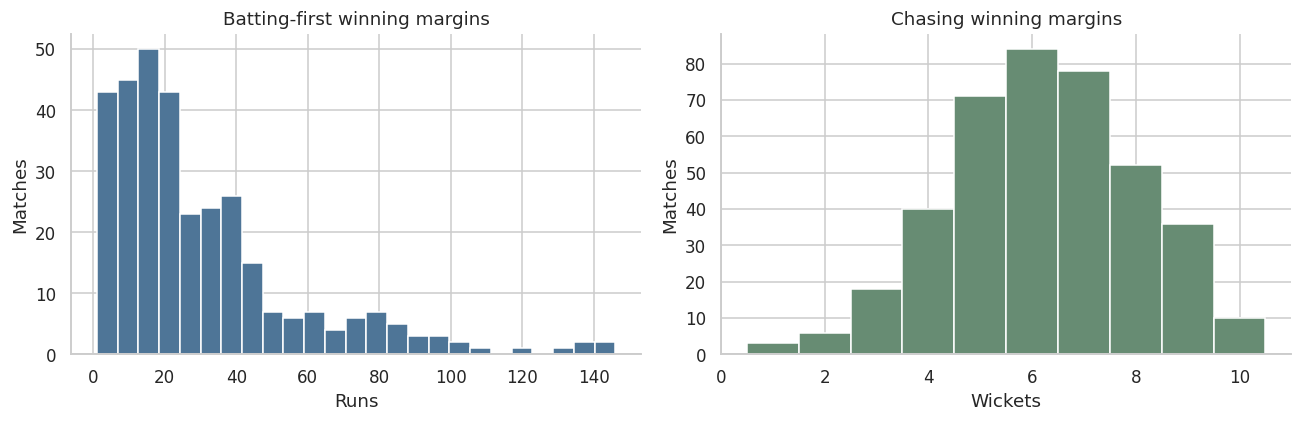

In [8]:
runs = regular.loc[regular.bat_first_win,"win_by_runs"]
wickets = regular.loc[regular.chase_win,"win_by_wickets"]
display(runs.describe().to_frame("run_margins")); display(wickets.describe().to_frame("wicket_margins"))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(runs,bins=25,color="#4e7597")
axes[0].set(xlabel="Runs",ylabel="Matches",title="Batting-first winning margins")
axes[1].hist(wickets,bins=np.arange(.5,11.5,1),color="#678c73")
axes[1].set(xlabel="Wickets",ylabel="Matches",title="Chasing winning margins")
plt.tight_layout(); plt.show()

**Answer.** The median batting-first winning margin is 22 runs across 326 matches. The median chasing margin is 6 wickets across 398 matches. These summaries describe different result types and should not be combined into a single numeric margin.

## Conclusion

Chennai Super Kings wins 61.0% of its decided matches in the archive. Among 724 normal unadjusted matches with unambiguous margins, chasing sides win 55.0% and toss winners win 52.2%. Neither proportion isolates a causal advantage.

Team win rates are more informative when their match counts are visible. Toss and chasing summaries show historical associations, with adjusted matches and ambiguous margins separated. Venue comparisons are useful starting points, but they do not isolate pitch conditions or team strength.
